Image Shape: (128, 128)
Unique Gray Levels: 255
Entropy: 7.7160 bits/pixel
Average Huffman Code Length: 7.7421 bits/pixel
Original Size: 131072 bits | Compressed Size: 126847 bits
Compression Ratio: 1.0333x
Lossless Reconstruction Verified: True


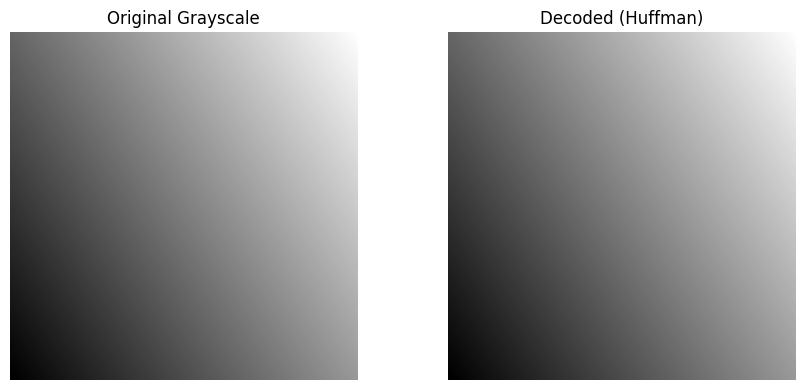

In [1]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

# 1. Load image if uploaded to /content/sample.png, else create a sample grayscale image
img_path = "/content/sample.png"
if os.path.exists(img_path):
    gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
else:
    x = np.linspace(0, 255, 128, dtype=np.uint8)
    y = np.linspace(255, 0, 128, dtype=np.uint8)
    xv, yv = np.meshgrid(x, y)
    gray = ((xv.astype(np.float32) * 0.6 + yv.astype(np.float32) * 0.4)).astype(np.uint8)

# 2. Huffman Tree construction
class HuffmanNode:
    def __init__(self, freq, symbol=None, left=None, right=None):
        self.freq = freq
        self.symbol = symbol
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.freq < other.freq

values, counts = np.unique(gray, return_counts=True)
total_pixels = gray.size
probs = counts / total_pixels

heap = [HuffmanNode(int(c), int(v)) for v, c in zip(values, counts)]
heapq.heapify(heap)

while len(heap) > 1:
    left = heapq.heappop(heap)
    right = heapq.heappop(heap)
    heapq.heappush(heap, HuffmanNode(left.freq + right.freq, None, left, right))

codes = {}
reverse_codes = {}

def generate_codes(node, current_code=""):
    if node is None:
        return
    if node.symbol is not None:
        code = current_code if current_code != "" else "0"
        codes[node.symbol] = code
        reverse_codes[code] = node.symbol
        return
    generate_codes(node.left, current_code + "0")
    generate_codes(node.right, current_code + "1")

generate_codes(heap[0])

# 3. Encode and Decode
flat_pixels = gray.flatten().tolist()
encoded_bits = "".join(codes[px] for px in flat_pixels)

decoded_pixels = []
buffer = ""
for bit in encoded_bits:
    buffer += bit
    if buffer in reverse_codes:
        decoded_pixels.append(reverse_codes[buffer])
        buffer = ""

reconstructed = np.array(decoded_pixels, dtype=np.uint8).reshape(gray.shape)
is_lossless = np.array_equal(gray, reconstructed)

# 4. Metrics
entropy = -np.sum(probs * np.log2(probs))
avg_length = len(encoded_bits) / total_pixels
orig_bits = total_pixels * 8
comp_ratio = orig_bits / len(encoded_bits)

print(f"Image Shape: {gray.shape}")
print(f"Unique Gray Levels: {len(values)}")
print(f"Entropy: {entropy:.4f} bits/pixel")
print(f"Average Huffman Code Length: {avg_length:.4f} bits/pixel")
print(f"Original Size: {orig_bits} bits | Compressed Size: {len(encoded_bits)} bits")
print(f"Compression Ratio: {comp_ratio:.4f}x")
print(f"Lossless Reconstruction Verified: {is_lossless}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

axes[1].imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Decoded (Huffman)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

Patch Shape: (8, 8) (64 pixels)
Final Interval Low : 2.040809514570803319e-2
Final Interval High: 2.040809514570803319e-2
Encoded Tag Value  : 2.040809514570803319e-2
Exact Lossless Decode: True


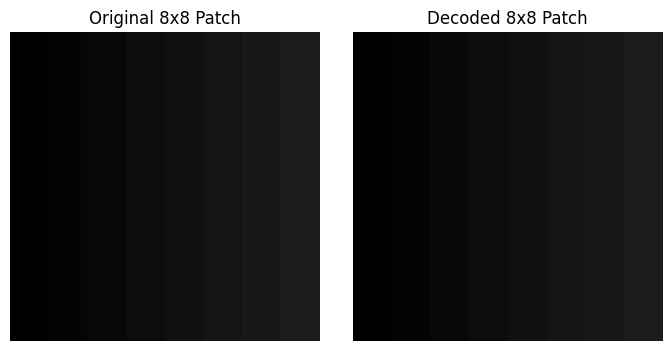

In [2]:
from decimal import Decimal, getcontext
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

getcontext().prec = 120

img_path = "/content/sample.png"
if os.path.exists(img_path):
    gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
else:
    gray = np.tile(np.arange(0, 256, 4, dtype=np.uint8), (64, 1))

# Use an 8x8 block (64 pixels) so high-precision Decimal stays fast and exact
patch = gray[:8, :8]
seq = patch.flatten().tolist()

unique_syms, counts = np.unique(seq, return_counts=True)
probs = {int(s): Decimal(int(c)) / Decimal(len(seq)) for s, c in zip(unique_syms, counts)}

# Build cumulative probability intervals [low, high)
cum_intervals = {}
low_acc = Decimal(0)
for sym, p in probs.items():
    high_acc = low_acc + p
    cum_intervals[sym] = (low_acc, high_acc)
    low_acc = high_acc

# Encode sequence
low = Decimal(0)
high = Decimal(1)
for sym in seq:
    s_low, s_high = cum_intervals[sym]
    width = high - low
    high = low + width * s_high
    low = low + width * s_low

tag = (low + high) / Decimal(2)

# Decode sequence
decoded = []
curr = tag
for _ in range(len(seq)):
    for sym, (s_low, s_high) in cum_intervals.items():
        if s_low <= curr < s_high:
            decoded.append(sym)
            curr = (curr - s_low) / (s_high - s_low)
            break

reconstructed_patch = np.array(decoded, dtype=np.uint8).reshape(patch.shape)
is_exact = np.array_equal(patch, reconstructed_patch)

print(f"Patch Shape: {patch.shape} ({len(seq)} pixels)")
print(f"Final Interval Low : {low:.18e}")
print(f"Final Interval High: {high:.18e}")
print(f"Encoded Tag Value  : {tag:.18e}")
print(f"Exact Lossless Decode: {is_exact}")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(patch, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original 8x8 Patch")
axes[0].axis("off")

axes[1].imshow(reconstructed_patch, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Decoded 8x8 Patch")
axes[1].axis("off")
plt.tight_layout()
plt.show()

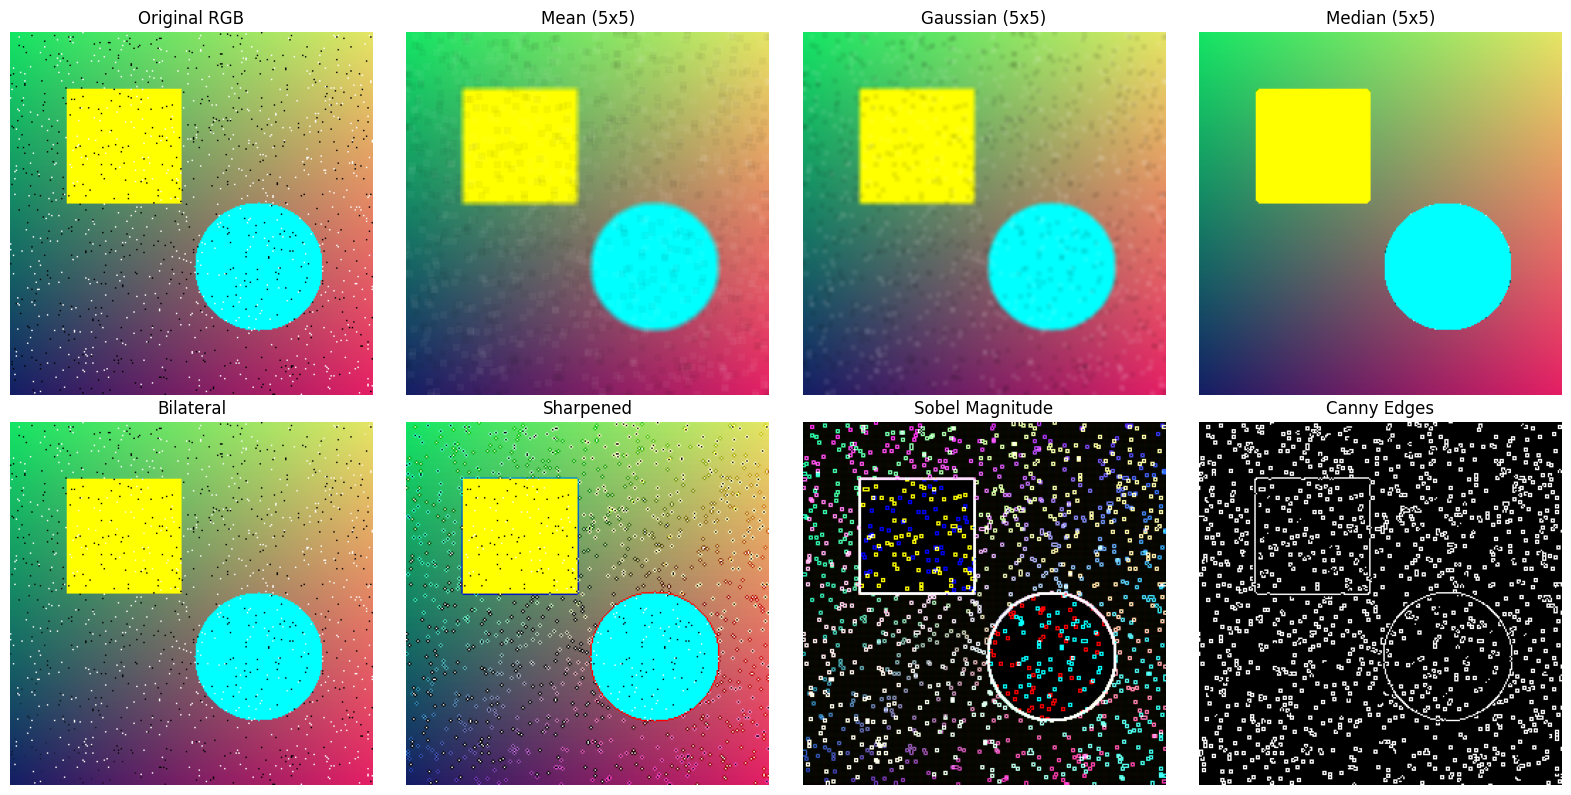

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

img_path = "/content/sample.png"
if os.path.exists(img_path):
    bgr = cv2.imread(img_path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
else:
    # Synthetic colorful RGB test image with shapes, gradients, and noise
    h, w = 256, 256
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    rgb[:, :, 0] = np.tile(np.linspace(20, 230, w, dtype=np.uint8), (h, 1))
    rgb[:, :, 1] = np.tile(np.linspace(230, 30, h, dtype=np.uint8)[:, None], (1, w))
    rgb[:, :, 2] = 100
    cv2.rectangle(rgb, (40, 40), (120, 120), (255, 255, 0), -1)
    cv2.circle(rgb, (175, 165), 45, (0, 255, 255), -1)
    rng = np.random.default_rng(42)
    salt_pepper = rng.random((h, w))
    rgb[salt_pepper < 0.01] = [255, 255, 255]
    rgb[salt_pepper > 0.99] = [0, 0, 0]

# 1. Smoothing / Denoising Filters
mean_blur = cv2.blur(rgb, (5, 5))
gaussian_blur = cv2.GaussianBlur(rgb, (5, 5), sigmaX=1.5)
median_blur = cv2.medianBlur(rgb, 5)
bilateral_filter = cv2.bilateralFilter(rgb, d=9, sigmaColor=75, sigmaSpace=75)

# 2. Sharpening Filter (Laplacian-based)
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)
sharpened = cv2.filter2D(rgb, -1, sharpen_kernel)

# 3. Edge Detection Filters (Sobel & Canny)
sobel_x = cv2.Sobel(rgb, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(rgb, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.clip(np.sqrt(sobel_x**2 + sobel_y**2), 0, 255).astype(np.uint8)

canny_edges = cv2.Canny(rgb, threshold1=80, threshold2=180)
canny_rgb = cv2.cvtColor(canny_edges, cv2.COLOR_GRAY2RGB)

results = [
    ("Original RGB", rgb),
    ("Mean (5x5)", mean_blur),
    ("Gaussian (5x5)", gaussian_blur),
    ("Median (5x5)", median_blur),
    ("Bilateral", bilateral_filter),
    ("Sharpened", sharpened),
    ("Sobel Magnitude", sobel_mag),
    ("Canny Edges", canny_rgb),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (title, im) in zip(axes.ravel(), results):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

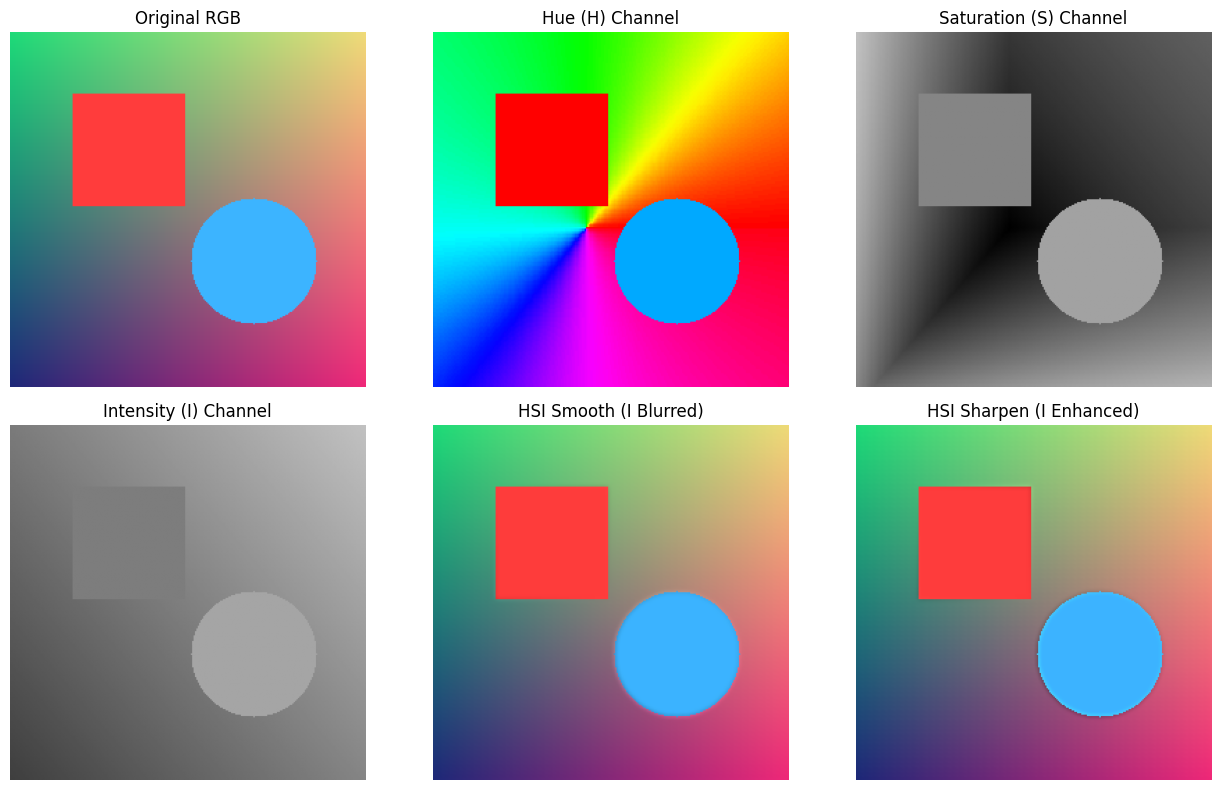

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def rgb_to_hsi(rgb_img):
    img = rgb_img.astype(np.float64) / 255.0
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]

    # Intensity I in [0, 1]
    intensity = (r + g + b) / 3.0

    # Saturation S in [0, 1]
    min_rgb = np.minimum(np.minimum(r, g), b)
    denom_s = r + g + b
    saturation = np.where(denom_s > 1e-12, 1.0 - (3.0 * min_rgb) / np.maximum(denom_s, 1e-12), 0.0)
    saturation = np.clip(saturation, 0.0, 1.0)

    # Hue H in radians [0, 2*pi)
    num = 0.5 * ((r - g) + (r - b))
    den = np.sqrt((r - g)**2 + (r - b) * (g - b)) + 1e-12
    theta = np.arccos(np.clip(num / den, -1.0, 1.0))
    hue = np.where(b <= g, theta, 2.0 * np.pi - theta)
    hue = np.where(saturation <= 1e-12, 0.0, hue)

    return np.stack([hue, saturation, intensity], axis=-1)

def hsi_to_rgb(hsi_img):
    h = hsi_img[:, :, 0] % (2.0 * np.pi)
    s = np.clip(hsi_img[:, :, 1], 0.0, 1.0)
    i = np.clip(hsi_img[:, :, 2], 0.0, 1.0)

    r = np.zeros_like(h)
    g = np.zeros_like(h)
    b = np.zeros_like(h)

    # Sector 1: 0 <= H < 2*pi/3
    m1 = (h >= 0) & (h < 2.0 * np.pi / 3.0)
    b[m1] = i[m1] * (1.0 - s[m1])
    r[m1] = i[m1] * (1.0 + (s[m1] * np.cos(h[m1])) / np.maximum(np.cos(np.pi / 3.0 - h[m1]), 1e-12))
    g[m1] = 3.0 * i[m1] - (r[m1] + b[m1])

    # Sector 2: 2*pi/3 <= H < 4*pi/3
    m2 = (h >= 2.0 * np.pi / 3.0) & (h < 4.0 * np.pi / 3.0)
    h2 = h[m2] - 2.0 * np.pi / 3.0
    r[m2] = i[m2] * (1.0 - s[m2])
    g[m2] = i[m2] * (1.0 + (s[m2] * np.cos(h2)) / np.maximum(np.cos(np.pi / 3.0 - h2), 1e-12))
    b[m2] = 3.0 * i[m2] - (r[m2] + g[m2])

    # Sector 3: 4*pi/3 <= H < 2*pi
    m3 = (h >= 4.0 * np.pi / 3.0) & (h <= 2.0 * np.pi)
    h3 = h[m3] - 4.0 * np.pi / 3.0
    g[m3] = i[m3] * (1.0 - s[m3])
    b[m3] = i[m3] * (1.0 + (s[m3] * np.cos(h3)) / np.maximum(np.cos(np.pi / 3.0 - h3), 1e-12))
    r[m3] = 3.0 * i[m3] - (g[m3] + b[m3])

    rgb_out = np.stack([r, g, b], axis=-1)
    return np.clip(rgb_out * 255.0, 0, 255).astype(np.uint8)

img_path = "/content/sample.png"
if os.path.exists(img_path):
    rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
else:
    h, w = 256, 256
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    rgb[:, :, 0] = np.tile(np.linspace(30, 240, w, dtype=np.uint8), (h, 1))
    rgb[:, :, 1] = np.tile(np.linspace(220, 40, h, dtype=np.uint8)[:, None], (1, w))
    rgb[:, :, 2] = 120
    cv2.rectangle(rgb, (45, 45), (125, 125), (255, 60, 60), -1)
    cv2.circle(rgb, (175, 165), 45, (60, 180, 255), -1)

hsi = rgb_to_hsi(rgb)
i_channel = hsi[:, :, 2]

# Smooth Intensity (I) channel with Gaussian blur
i_smooth = cv2.GaussianBlur(i_channel, (7, 7), sigmaX=2.0)
hsi_smooth = hsi.copy()
hsi_smooth[:, :, 2] = i_smooth
rgb_hsi_smooth = hsi_to_rgb(hsi_smooth)

# Sharpen Intensity (I) channel via unsharp masking
i_sharp = np.clip(i_channel + 1.2 * (i_channel - i_smooth), 0.0, 1.0)
hsi_sharp = hsi.copy()
hsi_sharp[:, :, 2] = i_sharp
rgb_hsi_sharp = hsi_to_rgb(hsi_sharp)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original RGB")
axes[0, 1].imshow(hsi[:, :, 0], cmap="hsv")
axes[0, 1].set_title("Hue (H) Channel")
axes[0, 2].imshow(hsi[:, :, 1], cmap="gray", vmin=0, vmax=1)
axes[0, 2].set_title("Saturation (S) Channel")

axes[1, 0].imshow(i_channel, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Intensity (I) Channel")
axes[1, 1].imshow(rgb_hsi_smooth)
axes[1, 1].set_title("HSI Smooth (I Blurred)")
axes[1, 2].imshow(rgb_hsi_sharp)
axes[1, 2].set_title("HSI Sharpen (I Enhanced)")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()